# 变分积分器求解大振幅单摆

- [周详](xiangzhou@whu.edu.cn)
- 武汉大学
- 2026年9月28日

例 2 结尾留了问题：能量的**严格守恒**是二次型的特权——非线性系统还剩什么？本例用全章的主角回答：**大振幅单摆**。第二章例 5 已经判过 RK2 的刑：能量无界漂移，$h = 0.1$ s 时 $51.7$ s 就把摆"注"过分界线 $E = 2mgL$，往复变旋转——数值误差改写了运动的**拓扑性质**。变分积分器能守住吗？

单摆的拉格朗日量（$\omega_0 = \sqrt{g/L}$，$z = \omega_0 h$）：

$$
L(\theta, \dot\theta) = \tfrac{1}{2}mL^2\dot\theta^2 + mgL\cos\theta
$$

仍用中点离散拉格朗日量 $L_d = h\,L(\text{中点位置}, \tfrac{\Delta\theta}{h})$。代入离散变分原理，DEL 为（**注意：$\theta_{k+1}$ 藏在 $\sin$ 里——方程是隐式的**）：

$$
2\theta_k - \theta_{k-1} - \theta_{k+1} = \frac{z^2}{2}\left[\sin\frac{\theta_{k-1}+\theta_k}{2} + \sin\frac{\theta_k+\theta_{k+1}}{2}\right]
$$

每步解一个一元方程：**牛顿法**——先用蛙跳格式预估 $\theta_{k+1}^{(0)} = 2\theta_k - \theta_{k-1}$，再校正；导数 $G' = 1 + \tfrac{z^2}{4}\cos\frac{\theta_k+\theta_{k+1}}{2} \geq 1 - \tfrac{z^2}{4} > 0$（$z < 2$），两三次迭代即到机器精度。节点动量与启动步同例 2：

$$
\frac{p_k}{mL^2} = \frac{\theta_{k+1}-\theta_k}{h} + \frac{\omega_0^2 h}{2}\sin\frac{\theta_k+\theta_{k+1}}{2},
\qquad
p_0 = mL^2\,\Omega_0 \;\Rightarrow\; \text{牛顿法解}\ \theta_1
$$

能量 $E = \tfrac{1}{2}mL^2\omega^2 + mgL(1-\cos\theta)$，参数与第二章例 5 完全一致（$\theta_0 = 120°$，$m = L = 1$，$g = 9.8$，$E_0 = 14.7$ J，分界线 $E = 2mgL = 19.6$ J，精确周期 $T = 2.7555$ s）。

**运行之前，先把你的预测写下来**：

1. RK2 的能量无界爬升、$51.7$ s 越过分界线——变分积分器的能量会怎么走？"严格守恒"的特权没了，剩下的是什么量级的保证？
2. 带宽随步长 $h$ 怎么缩？（后向误差分析预言 $O(h^2)$——每减半，带宽变几分之一？）
3. RK2 越界后摆变成了"旋转"——变分积分器的摆，$200$ s 后还在摆动区吗？

带着预测运行下面的代码，逐条对照。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.integrate import solve_ivp
from scipy.special import ellipk

# 字体配置：按操作系统自动选择中文字体，
# 西文与数学公式用 Times New Roman 风格（STIX）
import platform
system = platform.system()
if system == 'Darwin':
    cn_font = 'Songti SC'
elif system == 'Windows':
    cn_font = 'SimSun'
else:  # Linux
    cn_font = 'Noto Serif CJK SC'

plt.rcParams['font.family'] = [cn_font, 'Times New Roman']
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['axes.unicode_minus'] = False

In [2]:
def variational_pendulum(theta0, omega0, g, L, h, n_steps):
    """变分积分器（中点 L_d）求解单摆
    DEL 隐式：牛顿法解每步（蛙跳预估 + 校正）；启动步由 p_0 = m L^2 omega0 反解"""
    om0 = np.sqrt(g / L)
    z = om0 * h
    z2 = z * z
    t = np.arange(n_steps + 1) * h
    th = np.empty(n_steps + 2)                # 多算一个节点，末动量才够用
    th[0] = theta0
    s = theta0 + h * omega0                   # 启动步：牛顿法解 p_0 方程
    for _ in range(60):
        G = (s - theta0) + 0.5 * z2 * np.sin(0.5 * (theta0 + s)) - h * omega0
        dG = 1 + 0.25 * z2 * np.cos(0.5 * (theta0 + s))
        ds = -G / dG
        s += ds
        if abs(ds) < 1e-14:
            break
    th[1] = s
    n_iter = 0
    for k in range(1, n_steps + 1):
        s = 2 * th[k] - th[k - 1]             # 蛙跳预估
        sm = 0.5 * (th[k - 1] + th[k])
        for _ in range(60):                   # 牛顿校正
            G = (s - 2 * th[k] + th[k - 1]) + 0.5 * z2 * (np.sin(sm) + np.sin(0.5 * (th[k] + s)))
            dG = 1 + 0.25 * z2 * np.cos(0.5 * (th[k] + s))
            ds = -G / dG
            s += ds
            n_iter += 1
            if abs(ds) < 1e-14:
                break
        th[k + 1] = s
    mids = 0.5 * (th[:-1] + th[1:])
    om = (th[1:] - th[:-1]) / h + 0.5 * (g / L) * h * np.sin(mids)   # p_k / (m L^2)
    return t, th[:-1].copy(), om, n_iter / n_steps


def rk2_midpoint_pendulum(theta0, omega0, g, L, h, n_steps):
    """RK2 中点法求解单摆（第二章例 5 原格式）"""
    t = np.arange(n_steps + 1) * h
    th = np.empty(n_steps + 1)
    om = np.empty(n_steps + 1)
    th[0], om[0] = theta0, omega0
    for n in range(n_steps):
        om_mid = om[n] - 0.5 * h * (g / L) * np.sin(th[n])
        th_mid = th[n] + 0.5 * h * om[n]
        th[n + 1] = th[n] + h * om_mid
        om[n + 1] = om[n] - h * (g / L) * np.sin(th_mid)
    return t, th, om


def forward_euler_pendulum(theta0, omega0, g, L, h, n_steps):
    """前向欧拉法求解单摆（第二章例 5 原格式）"""
    t = np.arange(n_steps + 1) * h
    th = np.empty(n_steps + 1)
    om = np.empty(n_steps + 1)
    th[0], om[0] = theta0, omega0
    for n in range(n_steps):
        om[n + 1] = om[n] - h * (g / L) * np.sin(th[n])
        th[n + 1] = th[n] + h * om[n]
    return t, th, om


def measure_period(t, th):
    """过零点法测周期：上升过零点（线性插值）的平均间距"""
    s = np.where(np.diff(np.signbit(th)) & (th[1:] > 0))[0]
    tc = t[s] - th[s] * (t[s + 1] - t[s]) / (th[s + 1] - th[s])
    return np.mean(np.diff(tc))


# 参数（与第二章例 5 完全一致）
theta0 = np.deg2rad(120.0)
omega0 = 0.0
m, L, g = 1.0, 1.0, 9.8
om0 = np.sqrt(g / L)
T_exact = 4 * np.sqrt(L / g) * ellipk(np.sin(theta0 / 2)**2)
E0 = m * g * L * (1 - np.cos(theta0))
E_sep = 2 * m * g * L

h = 0.05                       # 主算例步长 (s)
t_end = 30.0                   # 总时间 (s)，约 11 个周期
n_steps = int(t_end / h)

t, th_vi, om_vi, avg_iter = variational_pendulum(theta0, omega0, g, L, h, n_steps)
_, th_rk, om_rk = rk2_midpoint_pendulum(theta0, omega0, g, L, h, n_steps)
ref = solve_ivp(lambda t, y: [y[1], -(g / L) * np.sin(y[0])], [0.0, t_end], [theta0, omega0],
                method='RK45', rtol=1e-11, atol=1e-12, dense_output=True)
th_ref = ref.sol(t)[0]

E_vi = 0.5 * m * L**2 * om_vi**2 + m * g * L * (1 - np.cos(th_vi))
E_rk = 0.5 * m * L**2 * om_rk**2 + m * g * L * (1 - np.cos(th_rk))

print(f'平均每步牛顿迭代次数：{avg_iter:.1f}')
print(f'{"":18}{"变分积分器":>16}{"RK2":>14}')
print(f'{"|θ-θ参考| 最大":17}{np.abs(th_vi - th_ref).max():>16.4f}{np.abs(th_rk - th_ref).max():>14.4f}')
print(f'{"|E/E0 - 1| 最大":17}{np.abs(E_vi / E0 - 1).max():>16.2e}{np.abs(E_rk / E0 - 1).max():>14.2e}')
print(f'{"末能量 E/E0":18}{E_vi[-1] / E0:>16.6f}{E_rk[-1] / E0:>14.6f}')
print(f'\n周期实测：变分积分器 {measure_period(t, th_vi):.4f} s，RK2 {measure_period(t, th_rk):.4f} s，精确 {T_exact:.4f} s')
print(f'周期相对误差：变分积分器 {measure_period(t, th_vi) / T_exact - 1:+.1e}，RK2 {measure_period(t, th_rk) / T_exact - 1:+.1e}')

平均每步牛顿迭代次数：3.0
                             变分积分器           RK2
|θ-θ参考| 最大                 0.0107        1.2156
|E/E0 - 1| 最大            1.53e-03      2.80e-02
末能量 E/E0                  1.000105      1.027775

周期实测：变分积分器 2.7553 s，RK2 2.7783 s，精确 2.7555 s
周期相对误差：变分积分器 -6.6e-05，RK2 +8.3e-03


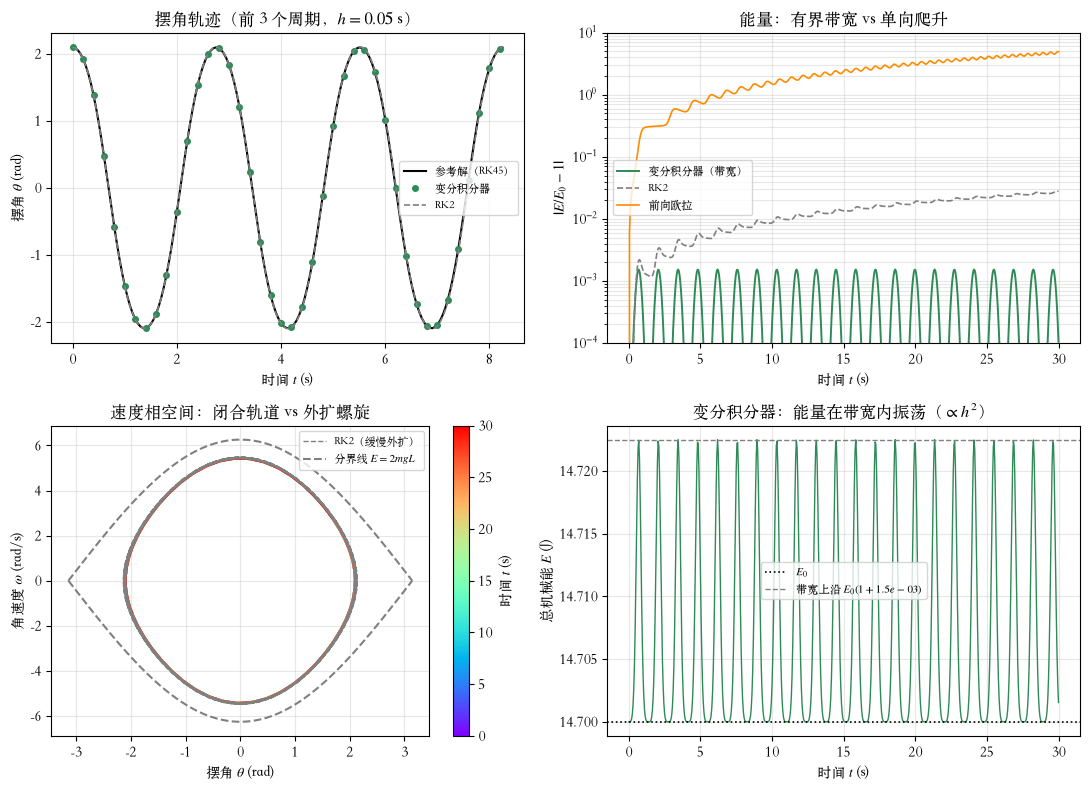

In [3]:
fig, axs = plt.subplots(2, 2, figsize=(11, 8))

# (a) θ(t) 局部放大：变分积分器贴着参考解，RK2 已现漂移
ax = axs[0, 0]
sel = t <= 3 * T_exact
ax.plot(t[sel], th_ref[sel], '-', color='black', lw=1.5, label='参考解（RK45）')
ax.plot(t[sel], th_vi[sel], 'o', color='seagreen', ms=4, markevery=4, label='变分积分器')
ax.plot(t[sel], th_rk[sel], '--', color='gray', lw=1.2, label='RK2')
ax.set_xlabel('时间 $t$ (s)')
ax.set_ylabel('摆角 $\\theta$ (rad)')
ax.set_title('摆角轨迹（前 3 个周期，$h = 0.05$ s）')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

# (b) 能量（对数纵轴，全程 30 s）
ax = axs[0, 1]
_, th_eu, om_eu = forward_euler_pendulum(theta0, omega0, g, L, h, n_steps)
E_eu = 0.5 * m * L**2 * om_eu**2 + m * g * L * (1 - np.cos(th_eu))
ax.semilogy(t, np.abs(E_vi / E0 - 1) + 1e-300, '-', color='seagreen', lw=1.4, label='变分积分器（带宽）')
ax.semilogy(t, np.abs(E_rk / E0 - 1), '--', color='gray', lw=1.2, label='RK2')
ax.semilogy(t, np.abs(E_eu / E0 - 1), '-', color='darkorange', lw=1.2, label='前向欧拉')
ax.set_ylim(1e-4, 1e1)
ax.set_xlabel('时间 $t$ (s)')
ax.set_ylabel('$|E/E_0 - 1|$')
ax.set_title('能量：有界带宽 vs 单向爬升')
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which='both')

# (c) 速度相空间 (θ, ω)：彩虹色显示时间方向
ax = axs[1, 0]
points = np.array([th_vi, om_vi]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
lc = LineCollection(segments, cmap='rainbow', array=t, lw=1.4)
ax.add_collection(lc)
cbar = fig.colorbar(lc, ax=ax)
cbar.set_label('时间 $t$ (s)')
ax.plot(th_rk, om_rk, '--', color='gray', lw=1.0, label='RK2（缓慢外扩）')
th_s = np.linspace(-np.pi, np.pi, 301)
ax.plot(th_s, 2 * om0 * np.cos(th_s / 2), '--', color='gray', lw=1.5)
ax.plot(th_s, -2 * om0 * np.cos(th_s / 2), '--', color='gray', lw=1.5, label='分界线 $E = 2mgL$')
ax.set_xlabel('摆角 $\\theta$ (rad)')
ax.set_ylabel('角速度 $\\omega$ (rad/s)')
ax.set_title('速度相空间：闭合轨道 vs 外扩螺旋')
ax.legend(fontsize=8, loc='upper right')
ax.grid(alpha=0.3)

# (d) 变分积分器能量细节（线性纵轴）：带宽内振荡，永不漂移
ax = axs[1, 1]
ax.plot(t, E_vi, '-', color='seagreen', lw=1.0)
ax.axhline(E0, ls=':', color='black', lw=1.2, label='$E_0$')
ax.axhline(E_vi.max(), ls='--', color='gray', lw=1.0,
           label=f'带宽上沿 $E_0(1 + {np.abs(E_vi / E0 - 1).max():.1e})$')
ax.set_xlabel('时间 $t$ (s)')
ax.set_ylabel('总机械能 $E$ (J)')
ax.set_title('变分积分器：能量在带宽内振荡（$\\propto h^2$）')
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout()
fig.savefig('outputs/3_simple_pendulum_variational.pdf', bbox_inches='tight')   # 矢量图导出
plt.show()

**对照预测 1–3（主算例 $h = 0.05$ s，$t = 30$ s）**：

- **能量有界**：变分积分器的 $|E/E_0 - 1|$ 被压在 $1.5\times 10^{-3}$ 的**带宽**内振荡——不是例 2 的严格恒等（非线性特权没了），但也绝不是 RK2 的单向爬升（同窗口已爬 $2.8\%$）或欧拉的爆炸。
- **摆角误差 $0.011$ rad 对 $1.216$ rad**：RK2 在 11 个周期里相位已漂出 $1.2$ rad（近 $70°$）；变分积分器贴着参考解。
- **周期几乎不减精度**：$2.7553$ s 对精确 $2.7555$ s（相对误差 $-6.6\times 10^{-5}$）。RK2 测得 $2.7783$ s（$+0.8\%$）——但这不是"钟慢"：RK2 的能量在涨、振幅在涨，**大振幅摆本来周期就长**，周期误差被能量漂移污染了。变分积分器的钟差（例 2 的 $-z^2/12$）在这里与修正能量的非线性频移大部分相消。

## 为什么：隐式的代价，有界的回报

- **隐式从哪来**：例 1、例 2 的 DEL 对 $x_{k+1}$ 是线性的（常数力/线性力）；$\sin\theta$ 一进场，$\theta_{k+1}$ 就藏进了方程——**每步解一个一元方程**。牛顿法以蛙跳为预估，$G' \geq 1 - z^2/4 > 0$ 保证单调收敛，实测平均每步 **3 次**迭代（一次右端计算的几倍，但仍远比"更高阶"便宜）。
- **变分结构的承诺（后向误差分析）**：变分积分器存在**修正能量** $\tilde E = E + h^2 E_2 + h^4 E_4 + \cdots$，数值轨道**精确守恒 $\tilde E$**（在 $t \lesssim e^{c/z}$ 的指数长时间内；这一保证的几何根源，留待后面的章节）。真实能量 $E$ 因此被锁在 $\tilde E_0 \pm O(h^2)$ 的**带宽**内永远**振荡**——系统性漂移被连根拔掉。例 2 的"恒等"是 $\tilde E = E$ 的特例（二次型）；本例 $\tilde E \neq E$，但带宽就是两者之差：$O(h^2)$。
- **RK2 为什么守不住**：RK2 没有这样的 $\tilde E$——能量误差是**随机游走式的净漂移**，$h = 0.1$ s 时 $51.7$ s 越过分界线（第二章例 5），摆动变旋转。
- **带宽的定量律**：下一节实测——$h$ 每减半，带宽精确缩小 $4$ 倍（$O(h^2)$ 兑现），且拉长 10 倍时间**一分不涨**。

## 长时间模拟：51.7 秒的命运改写

与第二章例 5 完全同规格：$h = 0.1$ s，$t = 200$ s。那里 RK2 在 $51.7$ s 把摆"注"过分界线、冲到 $E = 105$ J 的旋转区。

**先预测，再运行**：

1. 变分积分器的能量带宽（$h = 0.1$ s）多宽？摆会越过分界线吗？
2. 把 $h$ 减半再减半：带宽按什么比例缩？$200$ s 拉长到 $2000$ s，带宽会涨吗？
3. 速度相空间里，变分积分器的轨道 $200$ s 后是什么形状？

变分积分器：200 s 内不越界；E_末/E0 = 1.0002；max E = 14.79 J（带宽 6.1e-03）
RK2：t = 51.7 s 越过分界线；E_末/E0 = 7.0770；max E = 104.91 J（带宽 6.1e+00）
前向欧拉：t = 0.8 s 越过分界线；E_末/E0 = 29.5851；max E = 464.62 J（带宽 3.1e+01）

带宽 vs 步长（t = 200 s）：
  h = 0.200 s：带宽 = 2.429e-02
  h = 0.100 s：带宽 = 6.110e-03
  h = 0.050 s：带宽 = 1.530e-03
  h = 0.025 s：带宽 = 3.828e-04
  逐档缩小倍数：3.97, 3.99, 4.00（理论 4.00）

拉长 10 倍（t = 2000 s，2e4 步）：带宽仍为 6.110e-03，max E = 14.7898 J


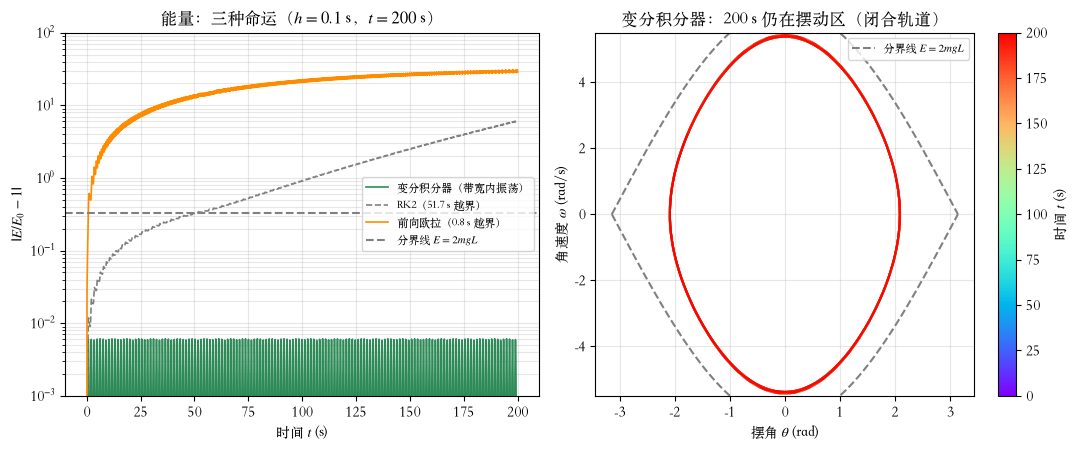

In [4]:
h_L = 0.1
n_L = int(200.0 / h_L)

tL, thL_vi, omL_vi, _ = variational_pendulum(theta0, omega0, g, L, h_L, n_L)
_, thL_rk, omL_rk = rk2_midpoint_pendulum(theta0, omega0, g, L, h_L, n_L)
_, thL_eu, omL_eu = forward_euler_pendulum(theta0, omega0, g, L, h_L, n_L)
EL_vi = 0.5 * m * L**2 * omL_vi**2 + m * g * L * (1 - np.cos(thL_vi))
EL_rk = 0.5 * m * L**2 * omL_rk**2 + m * g * L * (1 - np.cos(thL_rk))
EL_eu = 0.5 * m * L**2 * omL_eu**2 + m * g * L * (1 - np.cos(thL_eu))

for nm, E_L in (('变分积分器', EL_vi), ('RK2', EL_rk), ('前向欧拉', EL_eu)):
    k = np.argmax(E_L > E_sep) if (E_L > E_sep).any() else -1
    cross = f't = {tL[k]:.1f} s 越过分界线' if k >= 0 else '200 s 内不越界'
    print(f'{nm}：{cross}；E_末/E0 = {E_L[-1] / E0:.4f}；max E = {E_L.max():.2f} J（带宽 {np.abs(E_L / E0 - 1).max():.1e}）')

print('\n带宽 vs 步长（t = 200 s）：')
bands = []
for h_s in (0.2, 0.1, 0.05, 0.025):
    _, th_s, om_s, _ = variational_pendulum(theta0, omega0, g, L, h_s, int(200.0 / h_s))
    b = np.abs((0.5 * m * L**2 * om_s**2 + m * g * L * (1 - np.cos(th_s))) / E0 - 1).max()
    bands.append(b)
    print(f'  h = {h_s:5.3f} s：带宽 = {b:.3e}')
print(f'  逐档缩小倍数：{bands[0] / bands[1]:.2f}, {bands[1] / bands[2]:.2f}, {bands[2] / bands[3]:.2f}（理论 4.00）')

_, th_deep, om_deep, _ = variational_pendulum(theta0, omega0, g, L, h_L, int(2000.0 / h_L))
E_deep = 0.5 * m * L**2 * om_deep**2 + m * g * L * (1 - np.cos(th_deep))
print(f'\n拉长 10 倍（t = 2000 s，2e4 步）：带宽仍为 {np.abs(E_deep / E0 - 1).max():.3e}，max E = {E_deep.max():.4f} J')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.6))

# (a) 能量对决
ax1.semilogy(tL, np.abs(EL_vi / E0 - 1) + 1e-300, '-', color='seagreen', lw=1.2, label='变分积分器（带宽内振荡）')
ax1.semilogy(tL, np.abs(EL_rk / E0 - 1), '--', color='gray', lw=1.2, label='RK2（51.7 s 越界）')
ax1.semilogy(tL, np.abs(EL_eu / E0 - 1), '-', color='darkorange', lw=1.2, label='前向欧拉（0.8 s 越界）')
ax1.axhline(E_sep / E0 - 1, ls='--', color='gray', lw=1.5, label='分界线 $E = 2mgL$')
ax1.set_ylim(1e-3, 1e2)
ax1.set_xlabel('时间 $t$ (s)')
ax1.set_ylabel('$|E/E_0 - 1|$')
ax1.set_title('能量：三种命运（$h = 0.1$ s，$t = 200$ s）')
ax1.legend(fontsize=8, loc='center right')
ax1.grid(alpha=0.3, which='both')

# (b) 变分积分器的速度相空间：闭合花瓣，全程留在摆动区
points = np.array([thL_vi, omL_vi]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)
lc = LineCollection(segments, cmap='rainbow', array=tL, lw=1.2)
ax2.add_collection(lc)
cbar = fig.colorbar(lc, ax=ax2)
cbar.set_label('时间 $t$ (s)')
th_s = np.linspace(-np.pi, np.pi, 301)
ax2.plot(th_s, 2 * om0 * np.cos(th_s / 2), '--', color='gray', lw=1.5, label='分界线 $E = 2mgL$')
ax2.plot(th_s, -2 * om0 * np.cos(th_s / 2), '--', color='gray', lw=1.5)
ax2.set_xlabel('摆角 $\\theta$ (rad)')
ax2.set_ylabel('角速度 $\\omega$ (rad/s)')
ax2.set_xlim(-np.pi - 0.3, np.pi + 0.3)
ax2.set_ylim(-5.5, 5.5)
ax2.set_title('变分积分器：200 s 仍在摆动区（闭合轨道）')
ax2.legend(fontsize=8, loc='upper right')
ax2.grid(alpha=0.3)

plt.tight_layout()
fig.savefig('outputs/3_simple_pendulum_variational_long.pdf', bbox_inches='tight')   # 矢量图导出
plt.show()

**读图**：

- **命运改写**：变分积分器 $\max E = 14.79$ J，离分界线 $19.6$ J 还远得很——$200$ s 内**从未越界**；RK2 在 $51.7$ s 越界冲到 $105$ J（摆动变旋转），欧拉 $0.8$ s 就出局。同一个 $h$、同一个物理问题，几何性质决定了定性行为。
- **带宽 $O(h^2)$ 精确兑现**：$h = 0.2 \to 0.1 \to 0.05 \to 0.025$ s，带宽逐档缩小 **3.97、3.99、4.00** 倍——后向误差分析的预言分毫不差。$h = 0.1$ s 时带宽 $6.1\times 10^{-3}$（约 $0.09$ J）。
- **拉长 10 倍，一分不涨**：$t = 2000$ s（$2\times 10^4$ 步）带宽仍是 $6.110\times 10^{-3}$——"永远振荡、永不漂移"不是修辞，是变分结构的数学承诺（对 RK2，同样延长只会更糟）。
- **右图**：闭合的花瓣形轨道全程贴着 $E_0$ 等能线附近缓慢进动（钟差的缓慢累积），拓扑结构纹丝不动——摆动区出不去。

## 结论与思考

**先对照引言的三个预测**（能量怎么走？带宽怎么缩？越界了吗？），再记住几条：

- **非线性下，"恒等"退化为"有界"——但足够了**：变分积分器精确守恒修正能量 $\tilde E$ ⟹ 真实能量锁在 $O(h^2)$ 带宽内振荡。带宽随 $h$ 严格 $\propto h^2$（4.00 倍/档），拉长 10 倍时间不涨一分。
- **几何性质 = 定性行为的分水岭**：RK2 与变分积分器的差别不再是"精度高低"，而是"越界与不越界"——摆动与旋转的拓扑之别。这是第二章例 5 那句"要让能量长时间有界，需要格式本身的几何性质"的正面兑现。
- **隐式的代价很轻**：每步牛顿 3 次迭代（蛙跳预估 + 校正），换来无条件稳定与上述一切。
- **RK2 的周期误差（$+0.8\%$）是能量漂移的假象**：振幅涨 → 真实周期涨。变分积分器的钟差只有 $6.6\times 10^{-5}$，且与非线性频移大部分相消。

**思考**：

1. **旋转解**：把 $\Omega_0$ 加大到 $E_0 > 2mgL$（比如 $\Omega_0 = 5$ rad/s）。变分积分器的能量带宽还守得住吗？速度相空间里的轨道什么形状（$\theta$ 不再折回，怎么画）？
2. **端点 $L_d$（蛙跳版单摆）**：$L_d = \frac{mL^2(\Delta\theta)^2}{2h} - \frac{h}{2}[V(\theta_k) + V(\theta_{k+1})]$ 给出**显式**递推 $\theta_{k+1} = 2\theta_k - \theta_{k-1} - z^2\sin\theta_k$——不需要牛顿法。推导它，比较两者的带宽与每步成本（例 2 思考①的续集）。
3. **构造 $\tilde E$**：在小振幅极限下把例 2 的不变量翻译过来，拼出单摆修正能量的 $O(h^2)$ 显式形式，并数值验证它比 $E$ 本身守恒得好得多。
4. **耗散怎么进变分框架**：第二章例 7 的阻尼振子，能量本该衰减——变分积分器怎么做到"该衰则衰、不该衰则守"？（提示：离散 Lagrange–d'Alembert 原理。）